In [15]:
!pip -q install kagglehub

In [16]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download("gti-upm/leapgestrecog")

print("Dataset downloaded successfully!")
print("Dataset path:", dataset_path)

for root, dirs, files in os.walk(dataset_path):
    if files:
        print("Folder:", root)
        print("Sample files:", files[:3])
        break

100%|██████████| 2.13G/2.13G [00:21<00:00, 105MB/s] 

Extracting files...


Dataset downloaded successfully!
Dataset path: /root/.cache/kagglehub/datasets/gti-upm/leapgestrecog/versions/1
Folder: /root/.cache/kagglehub/datasets/gti-upm/leapgestrecog/versions/1/leapGestRecog/02/10_down
Sample files: ['frame_02_10_0093.png', 'frame_02_10_0109.png', 'frame_02_10_0090.png']


In [17]:
import os

for root, dirs, files in os.walk(dataset_path):
    image_files = [
        f for f in files
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    if image_files:
        print("Images found:", len(image_files))
        print("Example image:", os.path.join(root, image_files[0]))
        break

Images found: 200
Example image: /root/.cache/kagglehub/datasets/gti-upm/leapgestrecog/versions/1/leapGestRecog/02/10_down/frame_02_10_0093.png


In [18]:
import os

print("Dataset Path:", dataset_path)

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

Dataset Path: /root/.cache/kagglehub/datasets/gti-upm/leapgestrecog/versions/1
1/
  leapGestRecog/
    02/
    05/
    09/
    07/
    01/
    08/
    00/
    03/
    06/
    04/
  leapgestrecog/
    leapGestRecog/


In [20]:
# Cell 5: Collect image paths and gesture labels

import glob
import pandas as pd

image_paths = glob.glob(
    os.path.join(dataset_path, "**", "*.png"),
    recursive=True
)

image_paths += glob.glob(
    os.path.join(dataset_path, "**", "*.jpg"),
    recursive=True
)

image_paths = sorted(set(image_paths))

data = pd.DataFrame({
    "image_path": image_paths,
    "label": [os.path.basename(os.path.dirname(p)) for p in image_paths]
})

print("Total images:", len(data))
print("Total gesture classes:", data["label"].nunique())
print("\nImages per class:")
print(data["label"].value_counts().sort_index())

Total images: 40000
Total gesture classes: 10

Images per class:
label
01_palm          4000
02_l             4000
03_fist          4000
04_fist_moved    4000
05_thumb         4000
06_index         4000
07_ok            4000
08_palm_moved    4000
09_c             4000
10_down          4000
Name: count, dtype: int64


In [21]:
assert len(data) > 0, (
    "No images found. Check the dataset download and folder path."
)

assert data["label"].nunique() >= 2, (
    "Not enough gesture classes found."
)

print("Dataset verified successfully!")
print("Classes:", sorted(data["label"].unique()))

Dataset verified successfully!
Classes: ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']


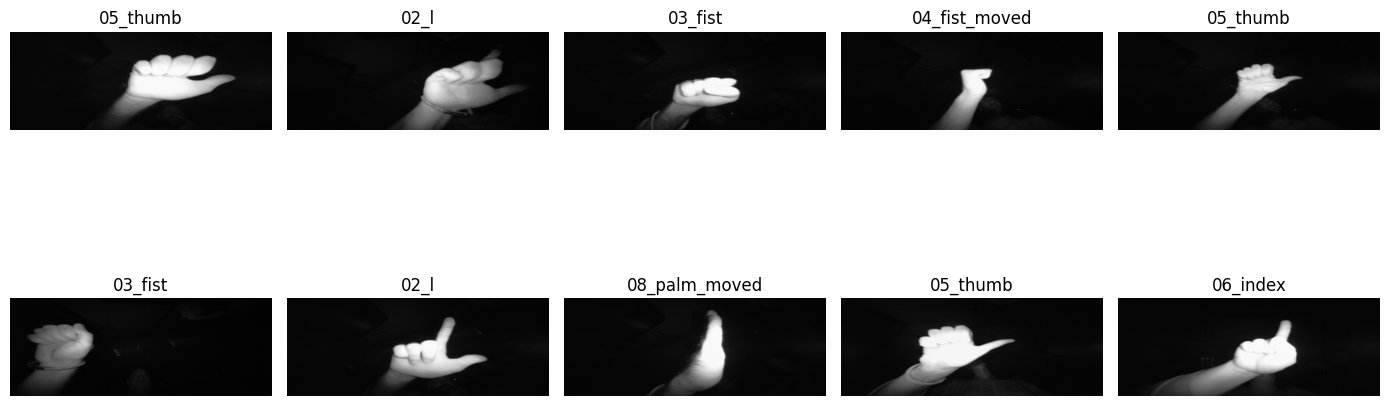

In [22]:
import matplotlib.pyplot as plt
from PIL import Image

sample = data.sample(
    n=min(10, len(data)),
    random_state=42
)

plt.figure(figsize=(14, 7))

for i, (_, row) in enumerate(sample.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(row["label"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    data,
    test_size=0.30,
    random_state=42,
    stratify=data["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

class_names = sorted(data["label"].unique())
num_classes = len(class_names)

class_to_id = {
    name: idx for idx, name in enumerate(class_names)
}

for df in [train_df, val_df, test_df]:
    df["label_id"] = df["label"].map(class_to_id)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Number of classes:", num_classes)

Training images: 28000
Validation images: 6000
Testing images: 6000
Number of classes: 10


In [24]:
import tensorflow as tf
import numpy as np

IMG_SIZE = 96
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=1,
        expand_animations=False
    )

    image.set_shape([None, None, 1])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

def make_dataset(df, training=False):
    paths = df["image_path"].values
    labels = df["label_id"].values.astype("int32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(df), 5000),
            seed=42
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("TensorFlow datasets ready!")

TensorFlow datasets ready!


In [25]:
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 96, 96, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 258,954 (1011.54 KB)

 Trainable params: 258,506 (1009.79 KB)

 Non-trainable params: 448 (1.75 KB)

In [27]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_hand_gesture_model.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

print("HAND GESTURE RECOGNITION TRAINING COMPLETED!")

Epoch 1/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 62s 71ms/step - accuracy: 1.0000 - loss: 5.9287e-05 - val_accuracy: 1.0000 - val_loss: 2.0027e-08 - learning_rate: 3.9063e-06
Epoch 2/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 73s 61ms/step - accuracy: 1.0000 - loss: 2.6900e-05 - val_accuracy: 1.0000 - val_loss: 1.8179e-08 - learning_rate: 3.9063e-06
Epoch 3/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 53s 61ms/step - accuracy: 1.0000 - loss: 2.2325e-05 - val_accuracy: 1.0000 - val_loss: 2.1437e-08 - learning_rate: 3.9063e-06
Epoch 4/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 53s 60ms/step - accuracy: 1.0000 - loss: 1.3890e-05 - val_accuracy: 1.0000 - val_loss: 1.8656e-08 - learning_rate: 1.9531e-06
Epoch 5/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 52s 59ms/step - accuracy: 1.0000 - loss: 1.6230e-05 - val_accuracy: 1.0000 - val_loss: 1.7166e-08 - learning_rate: 1.9531e-06
Epoch 6/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 51s 59ms/step - accuracy: 1.0000 - loss: 1.6893e-05 - val_accuracy: 1.0000 - val_loss: 1.7106e-08 - learning_rate: 1.0000e-06
Epoc

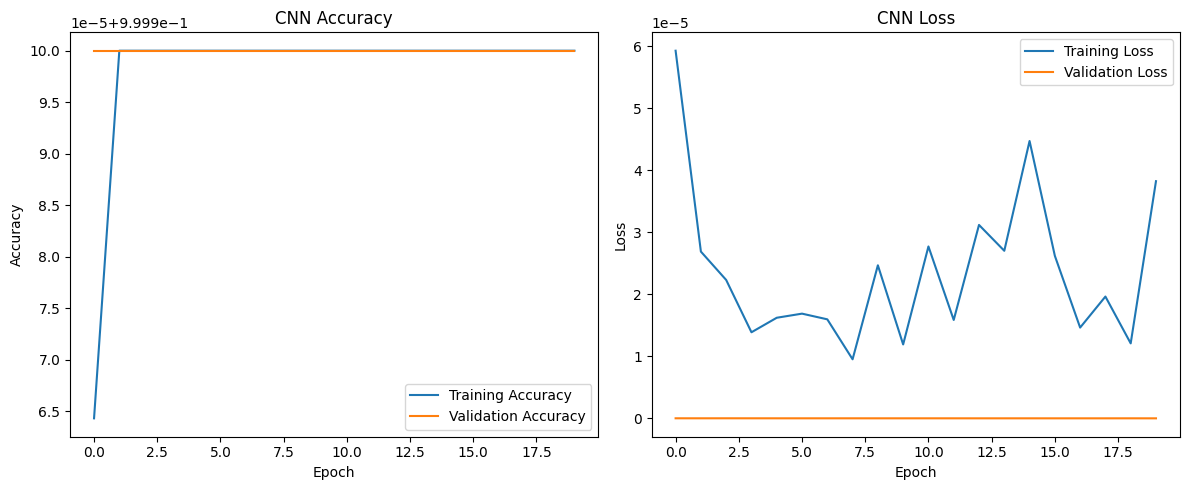

In [28]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [29]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

188/188 ━━━━━━━━━━━━━━━━━━━━ 17s 91ms/step - accuracy: 1.0000 - loss: 3.5265e-08
Test Accuracy: 100.00%
Test Loss: 0.0000


188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step
               precision    recall  f1-score   support

      01_palm       1.00      1.00      1.00       600
         02_l       1.00      1.00      1.00       600
      03_fist       1.00      1.00      1.00       600
04_fist_moved       1.00      1.00      1.00       600
     05_thumb       1.00      1.00      1.00       600
     06_index       1.00      1.00      1.00       600
        07_ok       1.00      1.00      1.00       600
08_palm_moved       1.00      1.00      1.00       600
         09_c       1.00      1.00      1.00       600
      10_down       1.00      1.00      1.00       600

     accuracy                           1.00      6000
    macro avg       1.00      1.00      1.00      6000
 weighted avg       1.00      1.00      1.00      6000



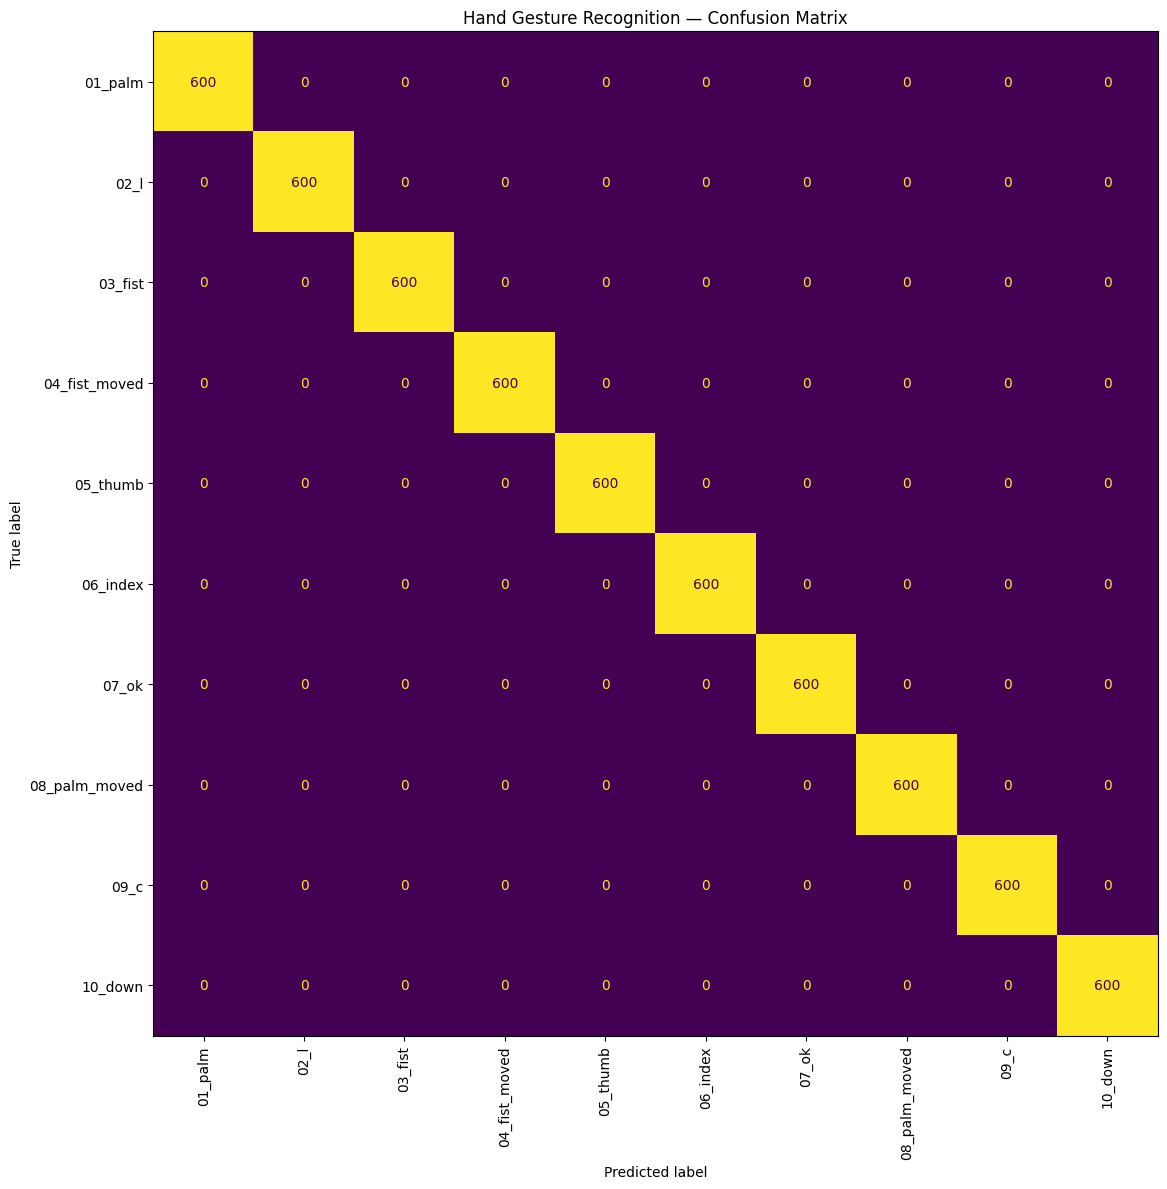

In [30]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 12))
display.plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)
plt.title("Hand Gesture Recognition — Confusion Matrix")
plt.tight_layout()
plt.show()

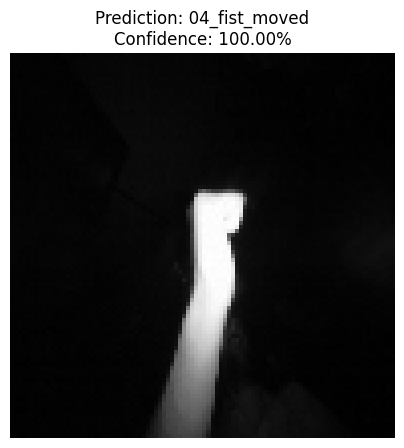

Predicted gesture: 04_fist_moved


In [31]:
def predict_gesture(image_path):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image,
        channels=1,
        expand_animations=False
    )
    image.set_shape([None, None, 1])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )
    image = tf.cast(image, tf.float32) / 255.0

    image_batch = tf.expand_dims(image, axis=0)

    probabilities = model.predict(
        image_batch,
        verbose=0
    )[0]

    predicted_id = int(np.argmax(probabilities))

    plt.figure(figsize=(5, 5))
    plt.imshow(tf.squeeze(image), cmap="gray")
    plt.title(
        f"Prediction: {class_names[predicted_id]}\n"
        f"Confidence: {probabilities[predicted_id] * 100:.2f}%"
    )
    plt.axis("off")
    plt.show()

    return class_names[predicted_id]

# Test dataset ki ek image par prediction
result = predict_gesture(test_df.iloc[0]["image_path"])
print("Predicted gesture:", result)

In [32]:
from google.colab import files

model.save("hand_gesture_recognition.keras")

print("Model saved successfully!")

files.download("hand_gesture_recognition.keras")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

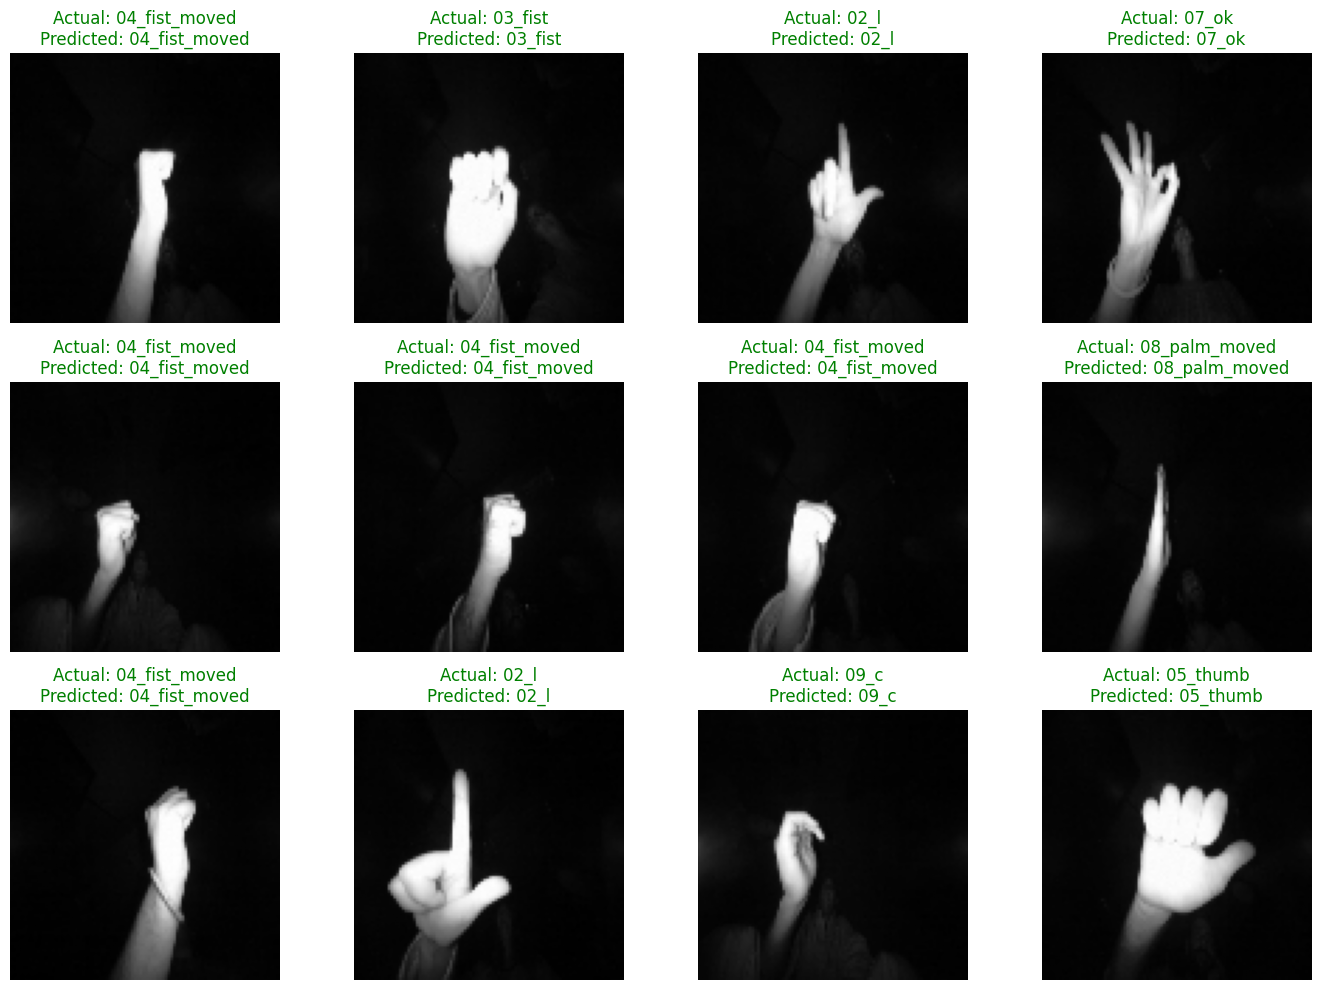

In [33]:
import matplotlib.pyplot as plt
import numpy as np

images, labels = next(iter(test_ds))
predictions = model.predict(images, verbose=0)

plt.figure(figsize=(14, 10))

for i in range(min(12, len(images))):
    predicted_id = np.argmax(predictions[i])
    actual_id = int(labels[i].numpy())

    plt.subplot(3, 4, i + 1)
    plt.imshow(tf.squeeze(images[i]), cmap="gray")

    color = "green" if predicted_id == actual_id else "red"

    plt.title(
        f"Actual: {class_names[actual_id]}\n"
        f"Predicted: {class_names[predicted_id]}",
        color=color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import accuracy_score

print("PER-CLASS ACCURACY\n")

for class_id, class_name in enumerate(class_names):
    mask = (y_true == class_id)

    if np.sum(mask) > 0:
        class_accuracy = accuracy_score(
            y_true[mask],
            y_pred[mask]
        )

        print(
            f"{class_name}: "
            f"{class_accuracy * 100:.2f}%"
        )

PER-CLASS ACCURACY

01_palm: 100.00%
02_l: 100.00%
03_fist: 100.00%
04_fist_moved: 100.00%
05_thumb: 100.00%
06_index: 100.00%
07_ok: 100.00%
08_palm_moved: 100.00%
09_c: 100.00%
10_down: 100.00%


In [35]:
results = test_df[["image_path", "label"]].copy()

results["actual_label"] = [
    class_names[i] for i in y_true
]

results["predicted_label"] = [
    class_names[i] for i in y_pred
]

results["confidence"] = np.max(y_prob, axis=1)

results["correct"] = (
    results["actual_label"] ==
    results["predicted_label"]
)

results.to_csv(
    "hand_gesture_predictions.csv",
    index=False
)

print("Prediction results saved!")
print(results.head())

from google.colab import files
files.download("hand_gesture_predictions.csv")

Prediction results saved!
                                              image_path          label  \
6639   /root/.cache/kagglehub/datasets/gti-upm/leapge...  04_fist_moved   
20401  /root/.cache/kagglehub/datasets/gti-upm/leapge...        03_fist   
6253   /root/.cache/kagglehub/datasets/gti-upm/leapge...           02_l   
39242  /root/.cache/kagglehub/datasets/gti-upm/leapge...          07_ok   
22790  /root/.cache/kagglehub/datasets/gti-upm/leapge...  04_fist_moved   

        actual_label predicted_label  confidence  correct  
6639   04_fist_moved   04_fist_moved         1.0     True  
20401        03_fist         03_fist         1.0     True  
6253            02_l            02_l         1.0     True  
39242          07_ok           07_ok         1.0     True  
22790  04_fist_moved   04_fist_moved         1.0     True  


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
import json

model.save("hand_gesture_recognition.keras")

with open("gesture_classes.json", "w") as f:
    json.dump(class_names, f, indent=4)

print("Model and class labels saved successfully!")

Model and class labels saved successfully!


In [37]:
print("=" * 45)
print(" HAND GESTURE RECOGNITION USING CNN")
print("=" * 45)

print("Dataset:", "LeapGestRecog")
print("Model:", "Convolutional Neural Network (CNN)")
print("Image Size:", f"{IMG_SIZE} x {IMG_SIZE}")
print("Number of Classes:", num_classes)
print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

print("=" * 45)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 45)

 HAND GESTURE RECOGNITION USING CNN
Dataset: LeapGestRecog
Model: Convolutional Neural Network (CNN)
Image Size: 96 x 96
Number of Classes: 10
Training Images: 28000
Validation Images: 6000
Testing Images: 6000
Test Accuracy: 100.00%
Test Loss: 0.0000
PROJECT COMPLETED SUCCESSFULLY!


In [38]:
from google.colab import files

files.download("hand_gesture_recognition.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>